---
title: "PA 8-2"
author: "Patrick Mori"

format:
  html:
    theme: minty
    toc: true
execute:
  echo: true
embed-resources: true

---


# Intro to Machine Learning; Linear Regression Models

In [3]:
import pandas as pd

import numpy as np

from plotnine import ggplot, aes, geom_point, geom_smooth, geom_line, labs, scale_x_continuous, theme_minimal
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error
import matplotlib
from matplotlib import font_manager

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.

In [2]:
tunes =pd.read_csv("https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv")

1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

In [7]:
X = tunes[["mean_millennial_recognition"]]
y = tunes["mean_gen_z_recognition"]

model_tunes = LinearRegression()
model_tunes.fit(X,y)

print("intercept:", round(model_tunes.intercept_, 4))
print("coef:     ", model_tunes.coef_.round(4))
print("R²:       ", round(model_tunes.score(X, y), 3))

intercept: -0.0481
coef:      [0.7067]
R²:        0.797


2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

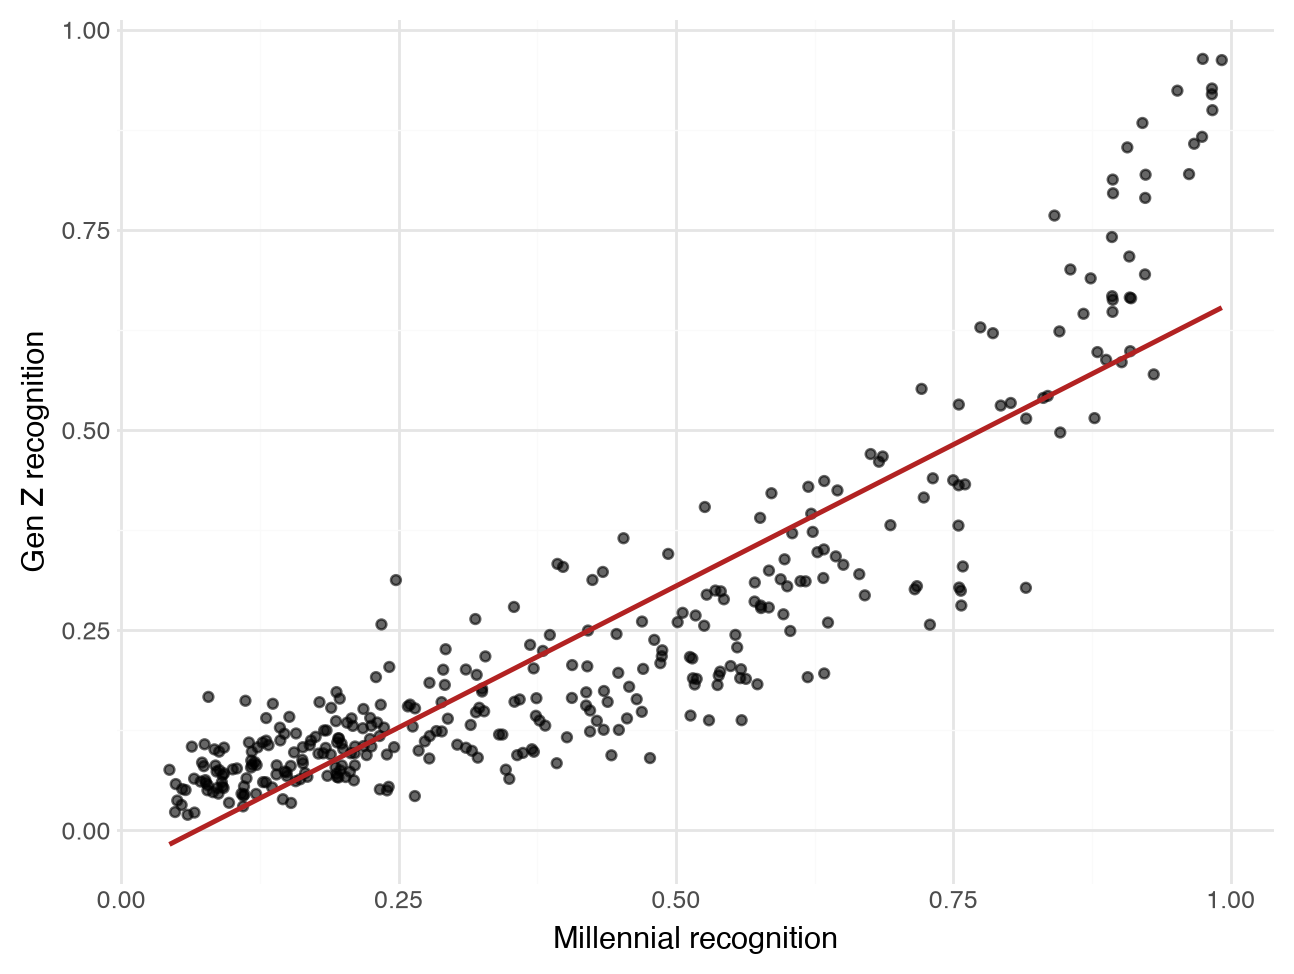

In [8]:
(
    ggplot(
        tunes,
        aes(
            x="mean_millennial_recognition",
            y="mean_gen_z_recognition"
        )
    )
    + geom_point(alpha=0.6)
    + geom_smooth(method="lm", se=False, color="firebrick")
    + labs(
        x="Millennial recognition",
        y="Gen Z recognition"
    )
    + theme_minimal()
)

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

You might want to take a log of Gen Z recognition because the scatterplot looks to be nonlinear. It seems to have a semi-parabolic shape so we should consider transformations to improve fit.

In [9]:
X = tunes[["mean_millennial_recognition"]]
y_log = np.log(tunes["mean_gen_z_recognition"])

log_model_tunes = LinearRegression()
log_model_tunes.fit(X, y_log)

print("intercept:", round(log_model_tunes.intercept_, 4))
print("coef:     ", log_model_tunes.coef_.round(4))
print("R²:       ", round(log_model_tunes.score(X, y_log), 3))

intercept: -2.9083
coef:      [2.7992]
R²:        0.823


4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

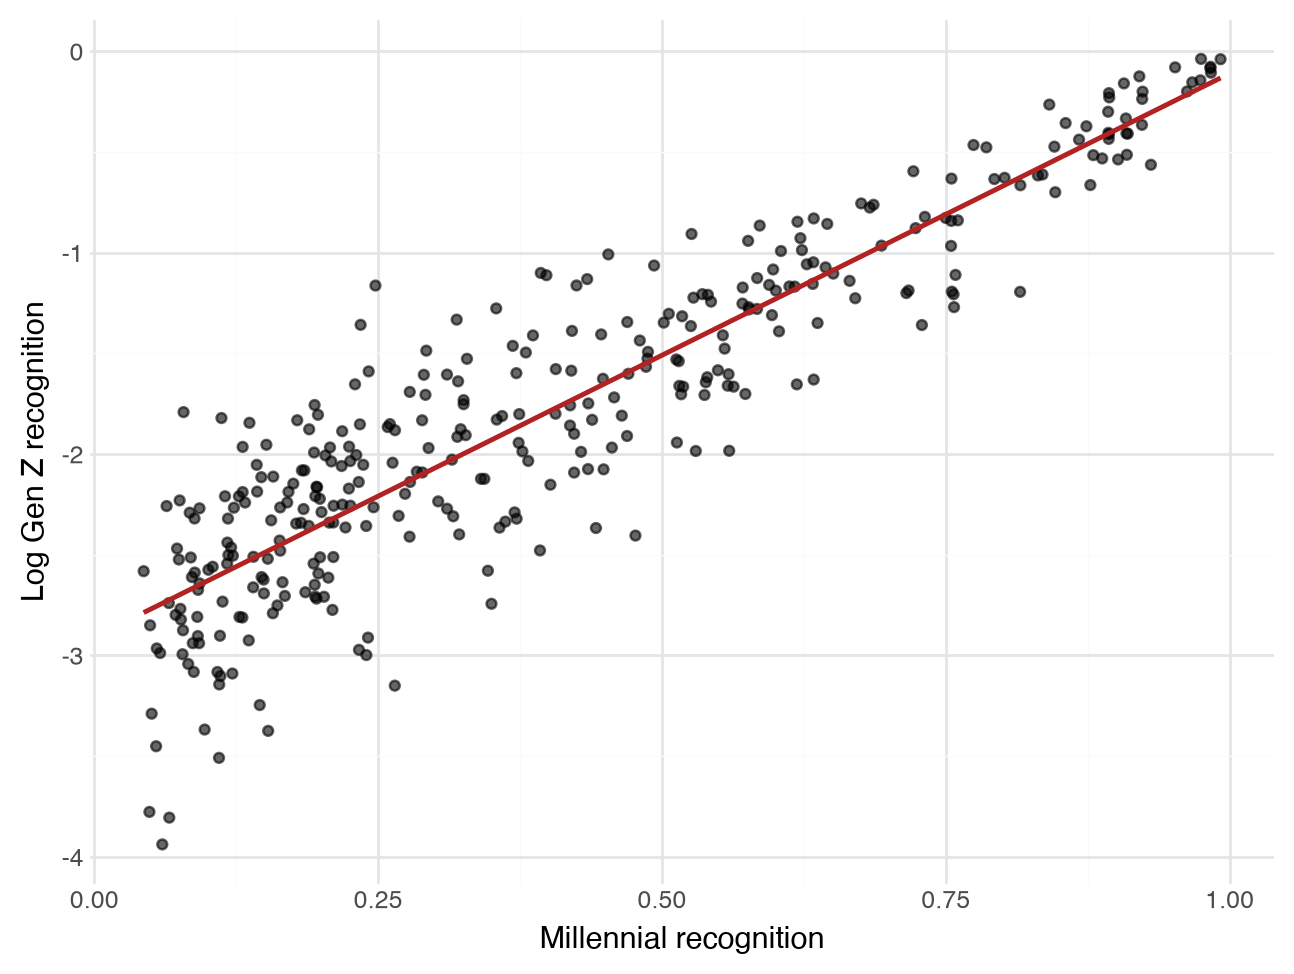

In [10]:
(
    ggplot(
        tunes,
        aes(
            x="mean_millennial_recognition",
            y=np.log(tunes["mean_gen_z_recognition"])
        )
    )
    + geom_point(alpha=0.6)
    + geom_smooth(method="lm", se=False, color="firebrick")
    + labs(
        x="Millennial recognition",
        y="Log Gen Z recognition"
    )
    + theme_minimal()
)

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

In [11]:
X_square = pd.DataFrame({
    "millennial_recognition": tunes["mean_millennial_recognition"],
    "millennial_recognition_squared":
        tunes["mean_millennial_recognition"] ** 2
})

y = tunes["mean_gen_z_recognition"]

square_model = LinearRegression()
square_model.fit(X_square, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.27, 1.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['millennial_recognition','millennial_recognition_squared']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1085
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2


In [13]:
square_model.coef_, square_model.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257645))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

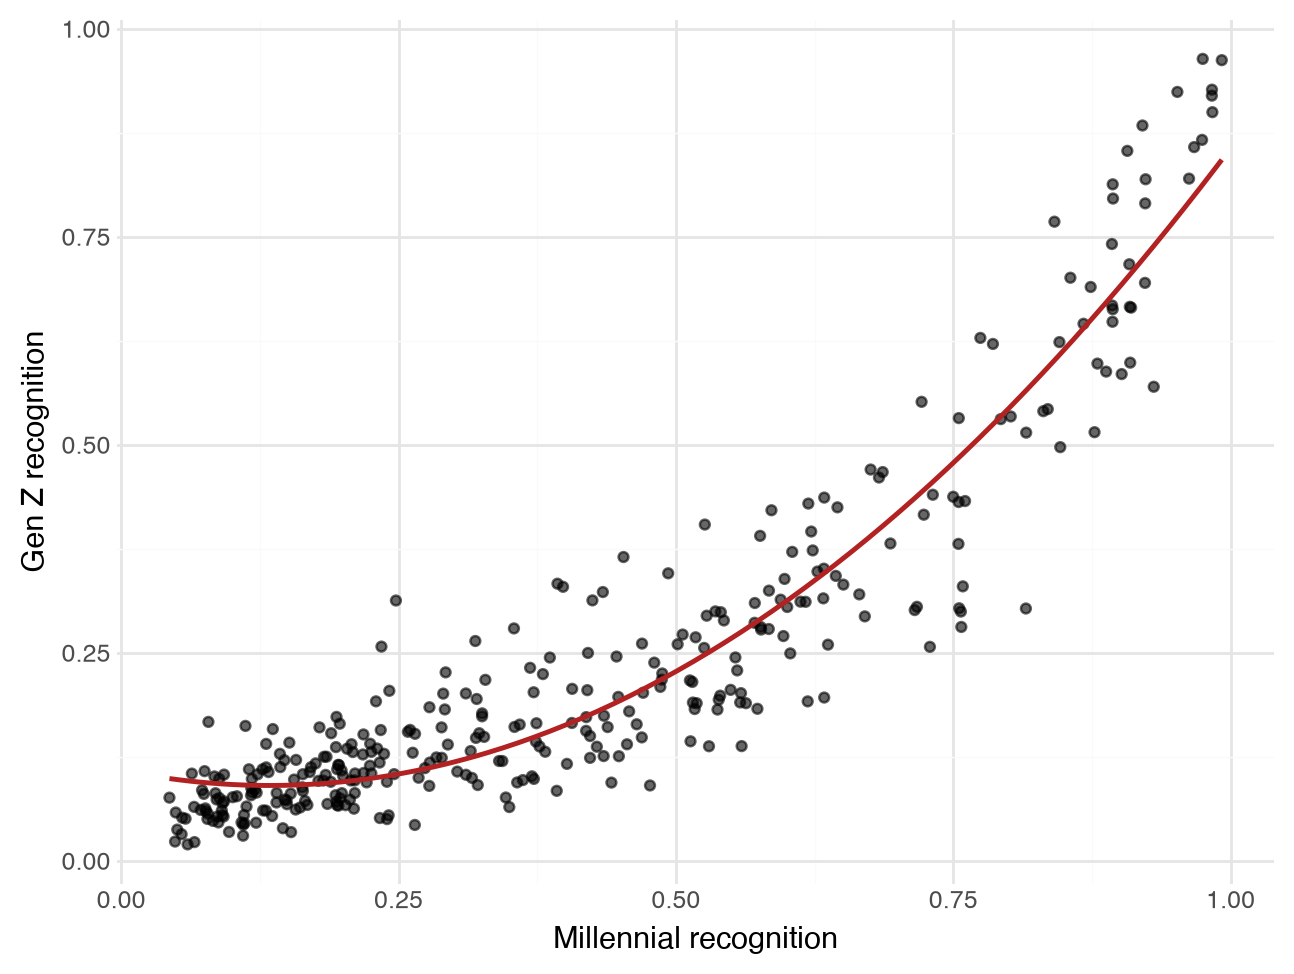

In [14]:
x_grid = np.linspace(
    tunes["mean_millennial_recognition"].min(),
    tunes["mean_millennial_recognition"].max(),
    200
)

X_grid = pd.DataFrame({
    "millennial_recognition": x_grid,
    "millennial_recognition_squared": x_grid ** 2
})

curve = pd.DataFrame({
    "mean_millennial_recognition": x_grid,
    "predicted_gen_z_recognition": square_model.predict(X_grid)
})

(
    ggplot(
        tunes,
        aes(
            x="mean_millennial_recognition",
            y="mean_gen_z_recognition"
        )
    )
    + geom_point(alpha=0.6)
    + geom_line(
        data=curve,
        mapping=aes(
            x="mean_millennial_recognition",
            y="predicted_gen_z_recognition"
        ),
        color="firebrick",
        size=1
    )
    + labs(
        x="Millennial recognition",
        y="Gen Z recognition"
    )
    + theme_minimal()
)

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

In [15]:
fantasy = tunes.loc[
    tunes["artist_song"] == "Mariah Carey|||Fantasy"
].iloc[0]

x_fantasy = fantasy["mean_millennial_recognition"]
actual = fantasy["mean_gen_z_recognition"]

# Input for the linear and log models
fantasy_linear = pd.DataFrame({
    "mean_millennial_recognition": [x_fantasy]
})

# Input for the polynomial model
fantasy_square = pd.DataFrame({
    "millennial_recognition": [x_fantasy],
    "millennial_recognition_squared": [x_fantasy ** 2]
})

linear_prediction = model_tunes.predict(fantasy_linear)[0]

log_prediction = np.exp(
    log_model_tunes.predict(fantasy_linear)[0]
)

square_prediction = square_model.predict(fantasy_square)[0]

results = pd.DataFrame({
    "Model": ["Linear", "Log", "Polynomial"],
    "Prediction": [
        linear_prediction,
        log_prediction,
        square_prediction
    ]
})

results["Actual"] = actual
results["Absolute error"] = abs(
    results["Prediction"] - results["Actual"]
)

results.round(4)

,Model,Prediction,Actual,Absolute error
0,Linear,0.3262,0.1375,0.1887
1,Log,0.2403,0.1375,0.1029
2,Polynomial,0.2505,0.1375,0.1130


My song has an actual Gen Z recognition of approximately 0.1375. The log model gives the closest prediction, approximately 0.2403, because it has the smallest absolute prediction error. Therefore, the log model performs best for this particular song.

8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

In [16]:
teen_spirit_linear = pd.DataFrame({
    "mean_millennial_recognition": [0.7]
})

teen_spirit_square = pd.DataFrame({
    "millennial_recognition": [0.7],
    "millennial_recognition_squared": [0.7 ** 2]
})

linear_prediction = model_tunes.predict(
    teen_spirit_linear
)[0]

log_prediction = np.exp(
    log_model_tunes.predict(teen_spirit_linear)[0]
)

square_prediction = square_model.predict(
    teen_spirit_square
)[0]

pd.DataFrame({
    "Model": ["Linear", "Log", "Polynomial"],
    "Predicted Gen Z recognition": [
        linear_prediction,
        log_prediction,
        square_prediction
    ]
}).round(4)

,Model,Predicted Gen Z recognition
0,Linear,0.4466
1,Log,0.3872
2,Polynomial,0.4178


The models predict Gen Z recognition between approximately 0.387 and 0.447. However, we cannot determine which model gives the best prediction because “Smells Like Teen Spirit” is not in the dataset, so we do not know its actual Gen Z recognition. Without the actual value, we cannot calculate and compare the prediction errors.

## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [17]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

In [18]:
df_fev["Smoker"] = (
    df_fev["Smoking status"] == "smoker"
).astype(int)

X_smoke = df_fev[["Smoker"]]
y_fev = df_fev["FEV"]

smoke_model = LinearRegression()
smoke_model.fit(X_smoke, y_fev)

print("Intercept:", round(smoke_model.intercept_, 4))
print("Coefficient:", smoke_model.coef_.round(4))
print("R²:", round(smoke_model.score(X_smoke, y_fev), 3))

Intercept: 2.5661
Coefficient: [0.7107]
R²: 0.06


2\. What are the predictions from this model? How could we have known that those would be the predictions?

In [19]:
prediction_data = pd.DataFrame({
    "Smoking status": ["non-smoker", "smoker"],
    "Smoker": [0, 1]
})

prediction_data["Predicted FEV"] = smoke_model.predict(
    prediction_data[["Smoker"]]
)

prediction_data

,Smoking status,Smoker,Predicted FEV
0,non-smoker,0,2.566143
1,smoker,1,3.276862


The predicted FEV is approximately 2.566 liters for a non-smoker and 3.277 liters for a smoker. We could have known these predictions in advance because a regression with one binary predictor produces the response mean for each group. The intercept is the mean FEV for non-smokers, and adding the smoking coefficient gives the mean FEV for smokers.

3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

Smokers have a higher average and predicted FEV than non-smokers. The predicted FEV is approximately 3.277 liters for smokers compared with 2.566 liters for non-smokers, a difference of about 0.711 liters. This is surprising because we might expect smoking to be associated with worse lung function and therefore lower FEV. However, this model shows only an association and does not establish that smoking causes higher FEV.

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

Smokers may appear to have higher FEV because the smokers in this dataset tend to be older and taller than the non-smokers. Older and taller individuals generally have larger lungs and therefore higher FEV. Age and height are confounding variables that the one-predictor model does not account for. Additionally, these subjects are young, so smokers may not have smoked long enough for substantial lung damage to appear. The smoker group is also much smaller than the non-smoker group. Therefore, the results do not show that smoking improves lung function; they reflect differences between the groups that are unrelated to smoking itself.

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

In [20]:
X_smoke_age = df_fev[["Smoker", "Age (months)"]]
y_fev = df_fev["FEV"]

smoke_age_model = LinearRegression()
smoke_age_model.fit(X_smoke_age, y_fev)

print("Intercept:", round(smoke_age_model.intercept_, 4))

pd.Series(
    smoke_age_model.coef_,
    index=X_smoke_age.columns,
    name="Coefficient"
).round(4)

Intercept: 0.3681


Smoker         -0.2172
Age (months)    0.0192
Name: Coefficient, dtype: float64

6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

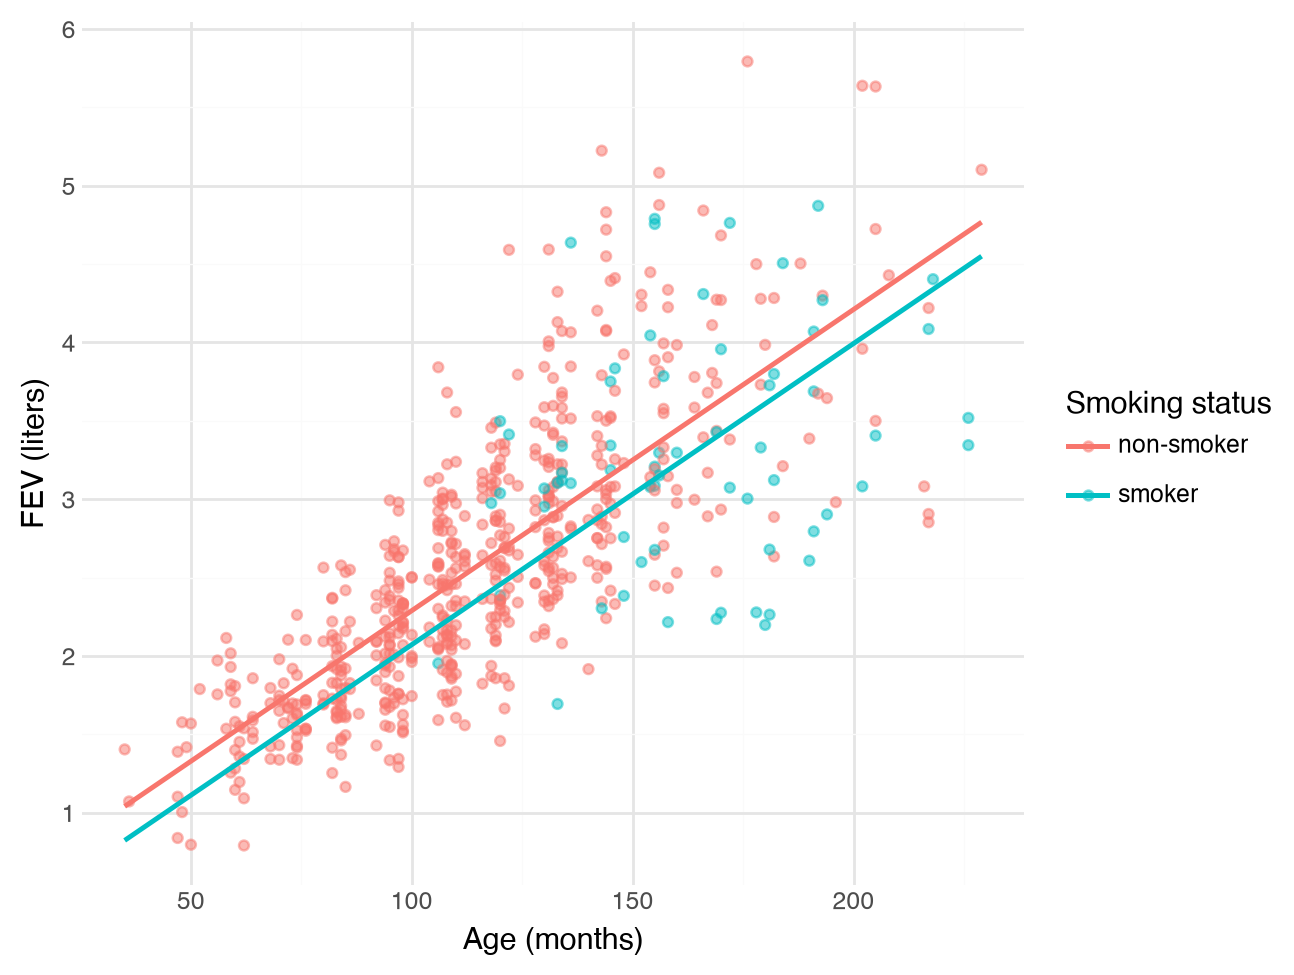

In [21]:
age_grid = np.linspace(
    df_fev["Age (months)"].min(),
    df_fev["Age (months)"].max(),
    200
)

model_lines = pd.DataFrame({
    "Age (months)": np.tile(age_grid, 2),
    "Smoker": np.repeat([0, 1], len(age_grid)),
    "Smoking status": np.repeat(
        ["non-smoker", "smoker"],
        len(age_grid)
    )
})

model_lines["Predicted FEV"] = smoke_age_model.predict(
    model_lines[["Smoker", "Age (months)"]]
)

(
    ggplot(
        df_fev,
        aes(
            x="Age (months)",
            y="FEV",
            color="Smoking status"
        )
    )
    + geom_point(alpha=0.5)
    + geom_line(
        data=model_lines,
        mapping=aes(
            x="Age (months)",
            y="Predicted FEV",
            color="Smoking status"
        ),
        size=1
    )
    + labs(
        x="Age (months)",
        y="FEV (liters)",
        color="Smoking status"
    )
    + theme_minimal()
)

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

In [22]:
df_fev["Smoker_Age_interaction"] = (
    df_fev["Smoker"] * df_fev["Age (months)"]
)

X_interaction = df_fev[
    ["Smoker", "Age (months)", "Smoker_Age_interaction"]
]

interaction_model = LinearRegression()
interaction_model.fit(X_interaction, y_fev)

print("Intercept:", round(interaction_model.intercept_, 4))

pd.Series(
    interaction_model.coef_,
    index=X_interaction.columns,
    name="Coefficient"
).round(4)

Intercept: 0.2595


Smoker                    1.8701
Age (months)              0.0202
Smoker_Age_interaction   -0.0131
Name: Coefficient, dtype: float64

8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

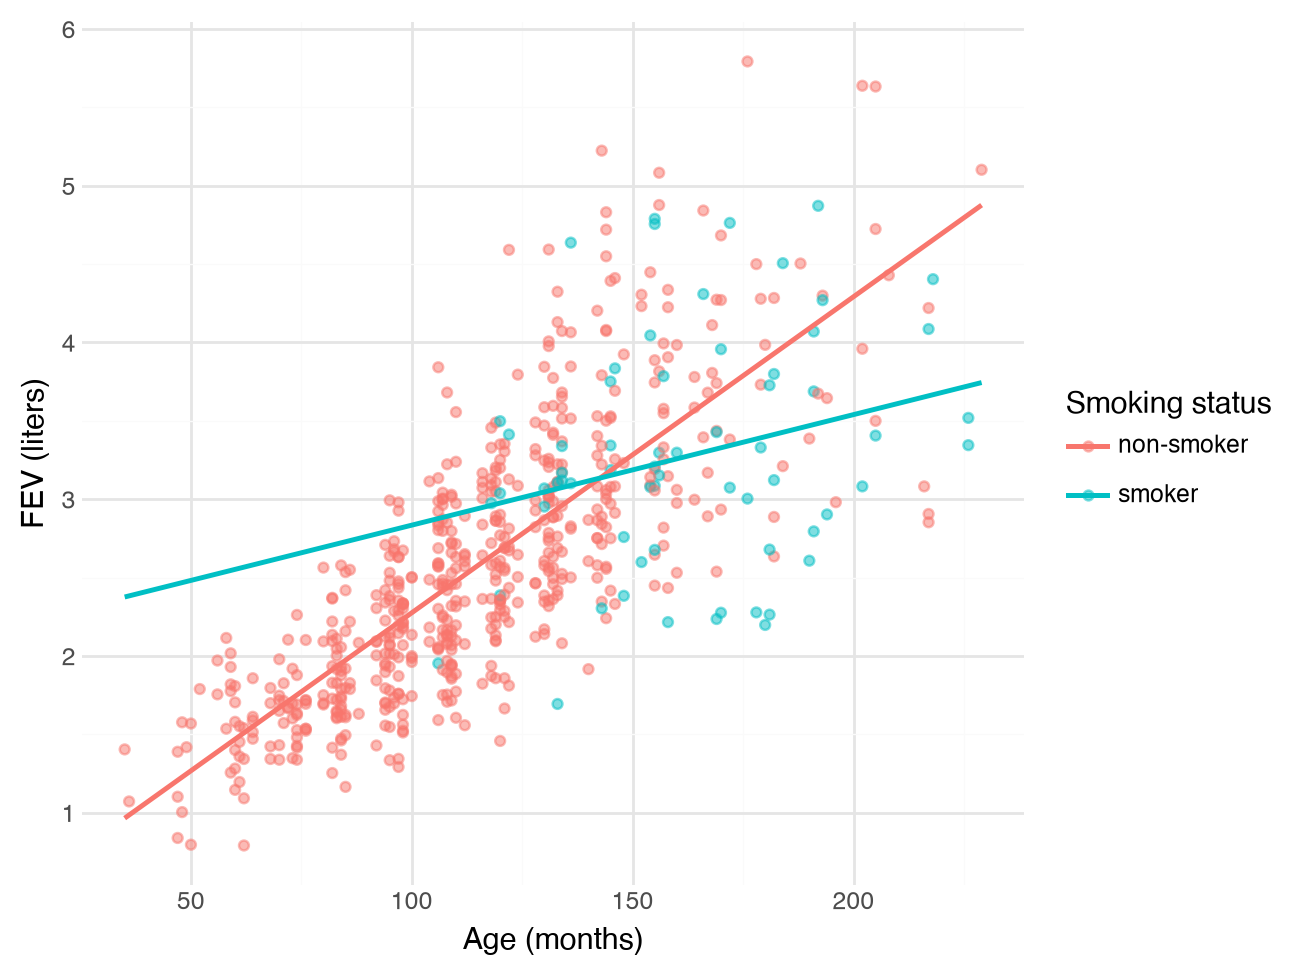

In [23]:
age_grid = np.linspace(
    df_fev["Age (months)"].min(),
    df_fev["Age (months)"].max(),
    200
)

interaction_lines = pd.DataFrame({
    "Age (months)": np.tile(age_grid, 2),
    "Smoker": np.repeat([0, 1], len(age_grid)),
    "Smoking status": np.repeat(
        ["non-smoker", "smoker"],
        len(age_grid)
    )
})

interaction_lines["Smoker_Age_interaction"] = (
    interaction_lines["Smoker"]
    * interaction_lines["Age (months)"]
)

interaction_lines["Predicted FEV"] = interaction_model.predict(
    interaction_lines[
        ["Smoker", "Age (months)", "Smoker_Age_interaction"]
    ]
)

(
    ggplot(
        df_fev,
        aes(
            x="Age (months)",
            y="FEV",
            color="Smoking status"
        )
    )
    + geom_point(alpha=0.5)
    + geom_line(
        data=interaction_lines,
        mapping=aes(
            x="Age (months)",
            y="Predicted FEV",
            color="Smoking status"
        ),
        size=1
    )
    + labs(
        x="Age (months)",
        y="FEV (liters)",
        color="Smoking status"
    )
    + theme_minimal()
)

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

In [24]:
pd.DataFrame({
    "Model": [
        "Smoking only",
        "Smoking + age",
        "Smoking + age + interaction"
    ],
    "R²": [
        smoke_model.score(X_smoke, y_fev),
        smoke_age_model.score(X_smoke_age, y_fev),
        interaction_model.score(X_interaction, y_fev)
    ]
}).round(3)

,Model,R²
0,Smoking only,0.060
1,Smoking + age,0.576
2,Smoking + age + interaction,0.592


In [25]:
train_index, test_index = train_test_split(
    df_fev.index,
    test_size=0.2,
    random_state=42
)

feature_sets = {
    "Smoking only": ["Smoker"],
    "Smoking + age": ["Smoker", "Age (months)"],
    "Smoking + age + interaction": [
        "Smoker",
        "Age (months)",
        "Smoker_Age_interaction"
    ]
}

results = []

for name, features in feature_sets.items():
    model = LinearRegression()

    model.fit(
        df_fev.loc[train_index, features],
        y_fev.loc[train_index]
    )

    predictions = model.predict(
        df_fev.loc[test_index, features]
    )

    results.append({
        "Model": name,
        "Test RMSE": root_mean_squared_error(
            y_fev.loc[test_index],
            predictions
        ),
        "Test R²": model.score(
            df_fev.loc[test_index, features],
            y_fev.loc[test_index]
        )
    })

pd.DataFrame(results).sort_values("Test RMSE").round(3)

,Model,Test RMSE,Test R²
2,Smoking + age + interaction,0.516,0.626
1,Smoking + age,0.519,0.622
0,Smoking only,0.819,0.057


The smoking-only model is clearly the weakest because it ignores age, which is strongly associated with FEV and differs between the smoking groups. Adding age substantially improves the model. The interaction model has the highest in-sample \(R^2\) and permits different age slopes for smokers and non-smokers, so it appears to fit best. However, it is also more complex. I would compare test-set or cross-validated RMSE values and examine residual plots. The preferred model would have the lowest out-of-sample RMSE without unnecessary complexity.